# AI-Based Landing Zone Safety Classification Using Drone Imagery

## Capstone Project

### Objective

The objective of this project is to build a Machine Learning model that classifies drone landing zones as **Safe** or **Unsafe** using terrain and environmental features extracted from aerial imagery.

This project demonstrates the complete machine learning workflow, from understanding the dataset to building and evaluating classification models that assist autonomous drones in identifying safe landing locations.

### Project Scope

The project includes the following stages:

- Data Understanding
- Exploratory Data Analysis (EDA)
- Data Preprocessing
- Feature Analysis
- Machine Learning Classification
- Model Evaluation
- Spatial Safety Analysis
- Drone Autonomy Interpretation
- Reflection and Future Improvements

### Expected Outcome

The final model predicts whether a potential landing zone is **Safe** or **Unsafe** based on terrain and environmental characteristics. The insights obtained from this analysis can support autonomous drone navigation, emergency landing decisions, and mission planning in real-world environments.

In [1]:
%pip install scikit-learn
%pip install seaborn
%pip install pandas


In [2]:
# =====================================
# Import Required Libraries
# =====================================

import warnings
warnings.filterwarnings('ignore')

# Numerical Libraries
import numpy as np
import pandas as pd

# Visualization Libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning Libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Set plotting style
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (10,6)

print("Libraries Imported Successfully")

Libraries Imported Successfully


In [3]:
import pandas as pd

url = "https://docs.google.com/spreadsheets/d/1tCQf9YVzj8zET1bjTlettAV5WfyeNpo4EBEjo5H1Z9Y/export?format=csv&gid=0"

df = pd.read_csv(url)

print(df.head())

   slope_deg  roughness  edge_density  ndvi_mean  shadow_fraction  \
0  10.483571   0.066756      0.099523   0.398224         0.297286   
1   7.308678   0.105711      0.377215   0.669015         0.057829   
2  11.238443   0.535800      0.067437   0.438767         0.198451   
3  15.615149   0.159571      0.182308   0.081362         0.379600   
4   6.829233   0.122880      0.129803   0.492456         0.110414   

   brightness_std  object_density  confidence_score  label  
0        0.067727        0.182327          0.741485      1  
1        0.147740        0.272118          0.837913      1  
2        0.132821        0.140229          0.802620      0  
3        0.124568        0.170602          0.777006      1  
4        0.156328        0.044424          0.885057      1  


In [4]:
df.head()


,slope_deg,roughness,edge_density,ndvi_mean,shadow_fraction,brightness_std,object_density,confidence_score,label
0,10.483571,0.066756,0.099523,0.398224,0.297286,0.067727,0.182327,0.741485,1
1,7.308678,0.105711,0.377215,0.669015,0.057829,0.147740,0.272118,0.837913,1
2,11.238443,0.535800,0.067437,0.438767,0.198451,0.132821,0.140229,0.802620,0
3,15.615149,0.159571,0.182308,0.081362,0.379600,0.124568,0.170602,0.777006,1
4,6.829233,0.122880,0.129803,0.492456,0.110414,0.156328,0.044424,0.885057,1


In [5]:
df.tail()

,slope_deg,roughness,edge_density,ndvi_mean,shadow_fraction,brightness_std,object_density,confidence_score,label
2995,8.387403,0.280633,0.187511,0.028223,0.028989,0.158808,0.092506,0.862487,1
2996,9.288763,0.280493,0.363842,0.253328,0.098522,0.207909,0.061030,0.773716,0
2997,1.791197,0.383695,0.474818,0.022864,0.300682,0.152782,0.502573,0.907883,0
2998,9.670882,0.338289,0.202693,0.032134,0.284579,0.087041,0.016859,0.862383,0
2999,7.223705,0.283629,0.456172,0.063612,0.275099,0.144804,0.374206,0.629910,0


## Why do we inspect the dataset?

Before training any machine learning model, it is important to understand:

- Number of rows
- Number of columns
- Data types
- Feature names
- Target column
- Missing values
- Duplicate records

This helps ensure the data is clean and suitable for model training.

In [6]:
print("Dataset Shape :", df.shape)

print("Number of Rows :", df.shape[0])

print("Number of Columns :", df.shape[1])

Dataset Shape : (3000, 9)
Number of Rows : 3000
Number of Columns : 9


In [7]:
print(df.columns)

Index(['slope_deg', 'roughness', 'edge_density', 'ndvi_mean',
       'shadow_fraction', 'brightness_std', 'object_density',
       'confidence_score', 'label'],
      dtype='object')


In [8]:
display(df)


,slope_deg,roughness,edge_density,ndvi_mean,shadow_fraction,brightness_std,object_density,confidence_score,label
0,10.483571,0.066756,0.099523,0.398224,0.297286,0.067727,0.182327,0.741485,1
1,7.308678,0.105711,0.377215,0.669015,0.057829,0.147740,0.272118,0.837913,1
2,11.238443,0.535800,0.067437,0.438767,0.198451,0.132821,0.140229,0.802620,0
3,15.615149,0.159571,0.182308,0.081362,0.379600,0.124568,0.170602,0.777006,1
4,6.829233,0.122880,0.129803,0.492456,0.110414,0.156328,0.044424,0.885057,1
...,...,...,...,...,...,...,...,...,...
2995,8.387403,0.280633,0.187511,0.028223,0.028989,0.158808,0.092506,0.862487,1
2996,9.288763,0.280493,0.363842,0.253328,0.098522,0.207909,0.061030,0.773716,0
2997,1.791197,0.383695,0.474818,0.022864,0.300682,0.152782,0.502573,0.907883,0
2998,9.670882,0.338289,0.202693,0.032134,0.284579,0.087041,0.016859,0.862383,0


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   slope_deg         3000 non-null   float64
 1   roughness         3000 non-null   float64
 2   edge_density      3000 non-null   float64
 3   ndvi_mean         3000 non-null   float64
 4   shadow_fraction   3000 non-null   float64
 5   brightness_std    3000 non-null   float64
 6   object_density    3000 non-null   float64
 7   confidence_score  3000 non-null   float64
 8   label             3000 non-null   int64  
dtypes: float64(8), int64(1)
memory usage: 211.1 KB


In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
slope_deg,3000.0,8.257786,4.729597,0.000000,4.862294,8.121824,11.367954,27.631189
roughness,3000.0,0.287347,0.157635,0.005368,0.167848,0.266516,0.390529,0.819733
edge_density,3000.0,0.335261,0.176202,0.000868,0.198709,0.319744,0.451383,0.901881
ndvi_mean,3000.0,0.397403,0.229965,0.000004,0.196411,0.398755,0.589366,0.799831
shadow_fraction,3000.0,0.245188,0.142418,0.005999,0.134075,0.224382,0.337315,0.756748
brightness_std,3000.0,0.151231,0.050393,-0.018778,0.117025,0.151421,0.186058,0.314608
object_density,3000.0,0.219207,0.130930,0.004051,0.120339,0.196254,0.298400,0.765969
confidence_score,3000.0,0.775345,0.100204,0.600259,0.689372,0.776927,0.863509,0.949867
label,3000.0,0.550000,0.497577,0.000000,0.000000,1.000000,1.000000,1.000000


In [11]:
print(df.isnull().sum())

slope_deg           0
roughness           0
edge_density        0
ndvi_mean           0
shadow_fraction     0
brightness_std      0
object_density      0
confidence_score    0
label               0
dtype: int64


In [12]:
print("Duplicate Records :", df.duplicated().sum())

Duplicate Records : 0


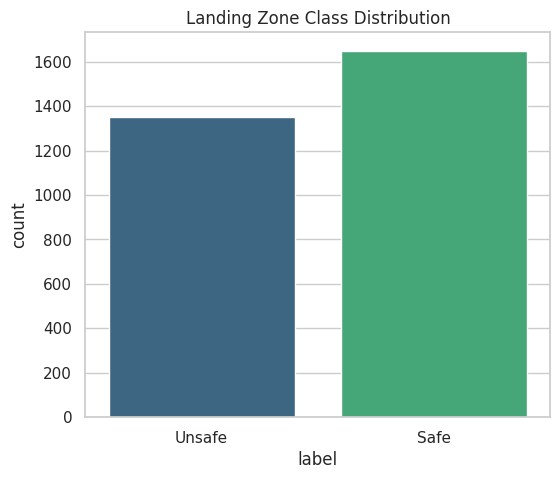

In [13]:
plt.figure(figsize=(6,5))

sns.countplot(
    data=df,
    x="label",
    palette="viridis"
)

plt.xticks([0,1],["Unsafe","Safe"])

plt.title("Landing Zone Class Distribution")

plt.show()

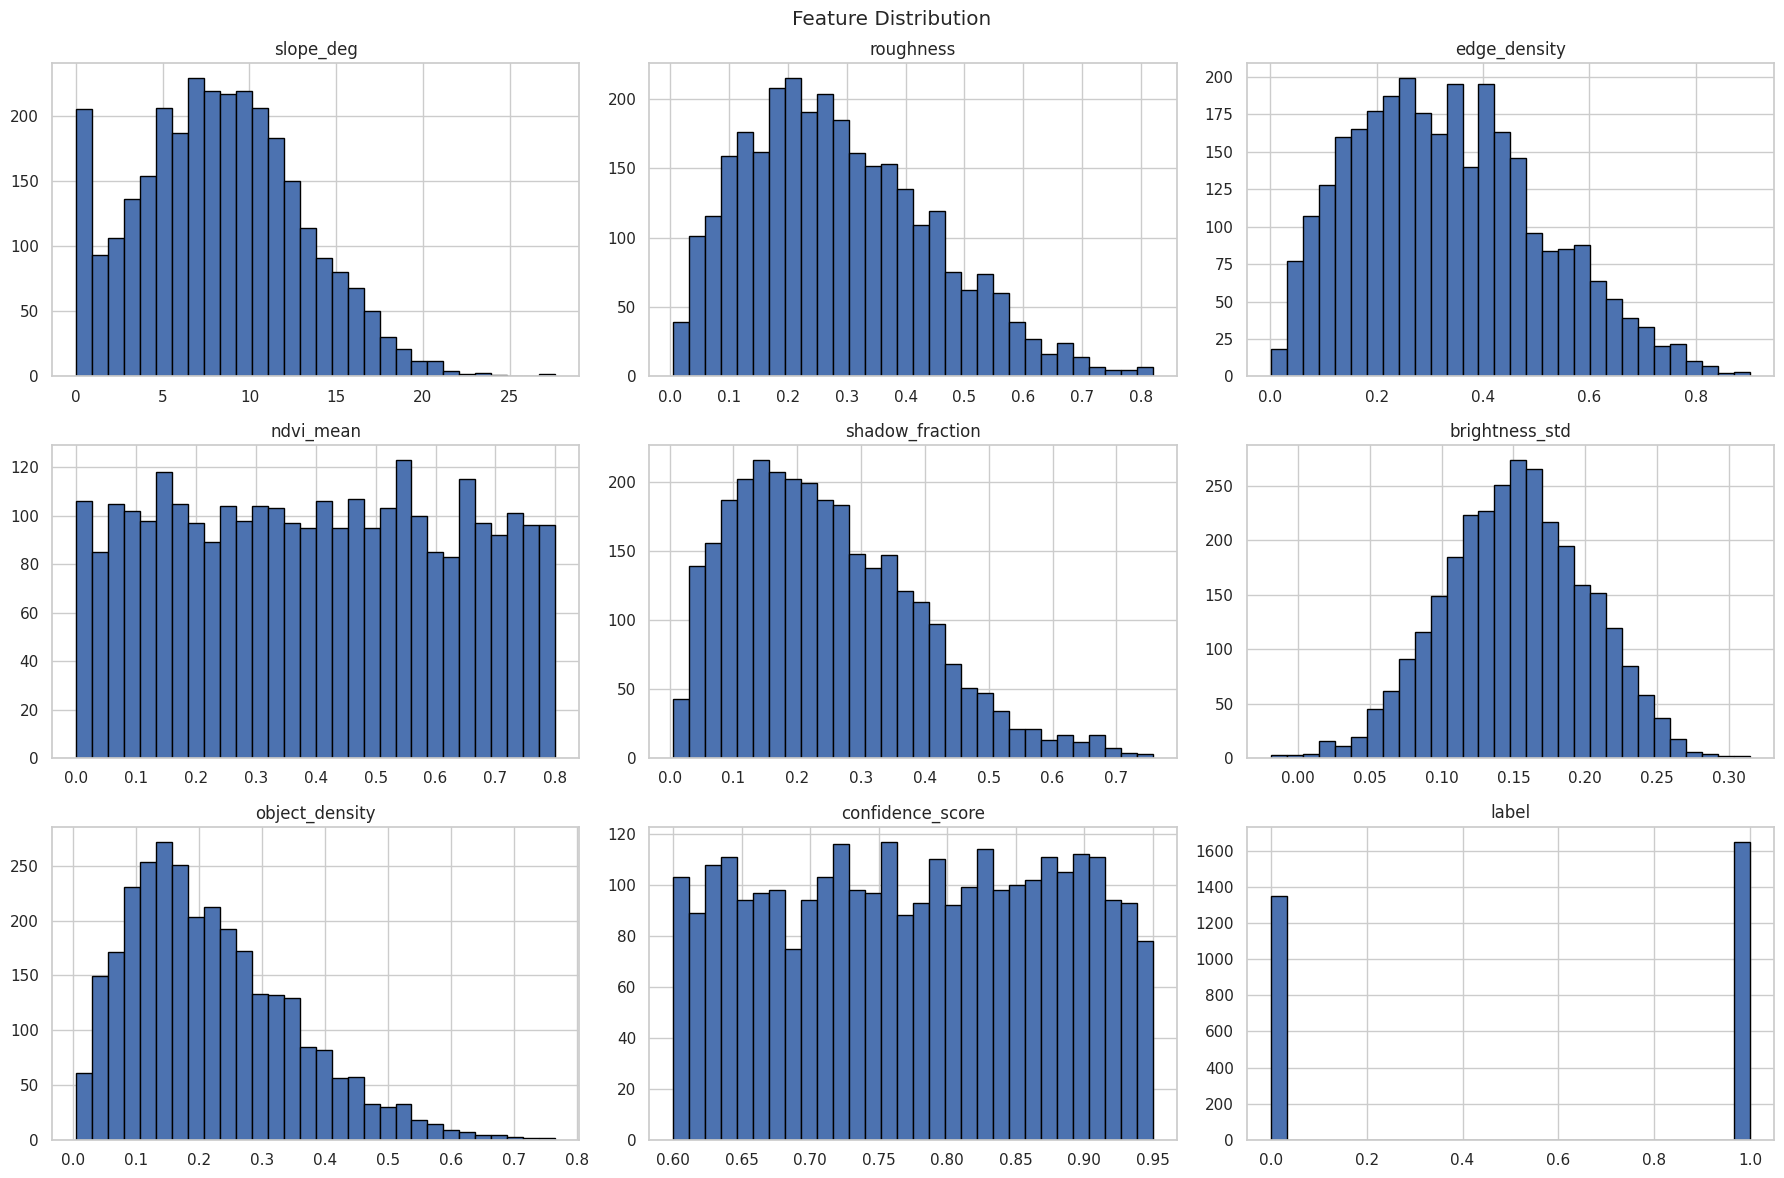

In [14]:
df.hist(
    figsize=(18,12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Feature Distribution")

plt.tight_layout()

plt.show()

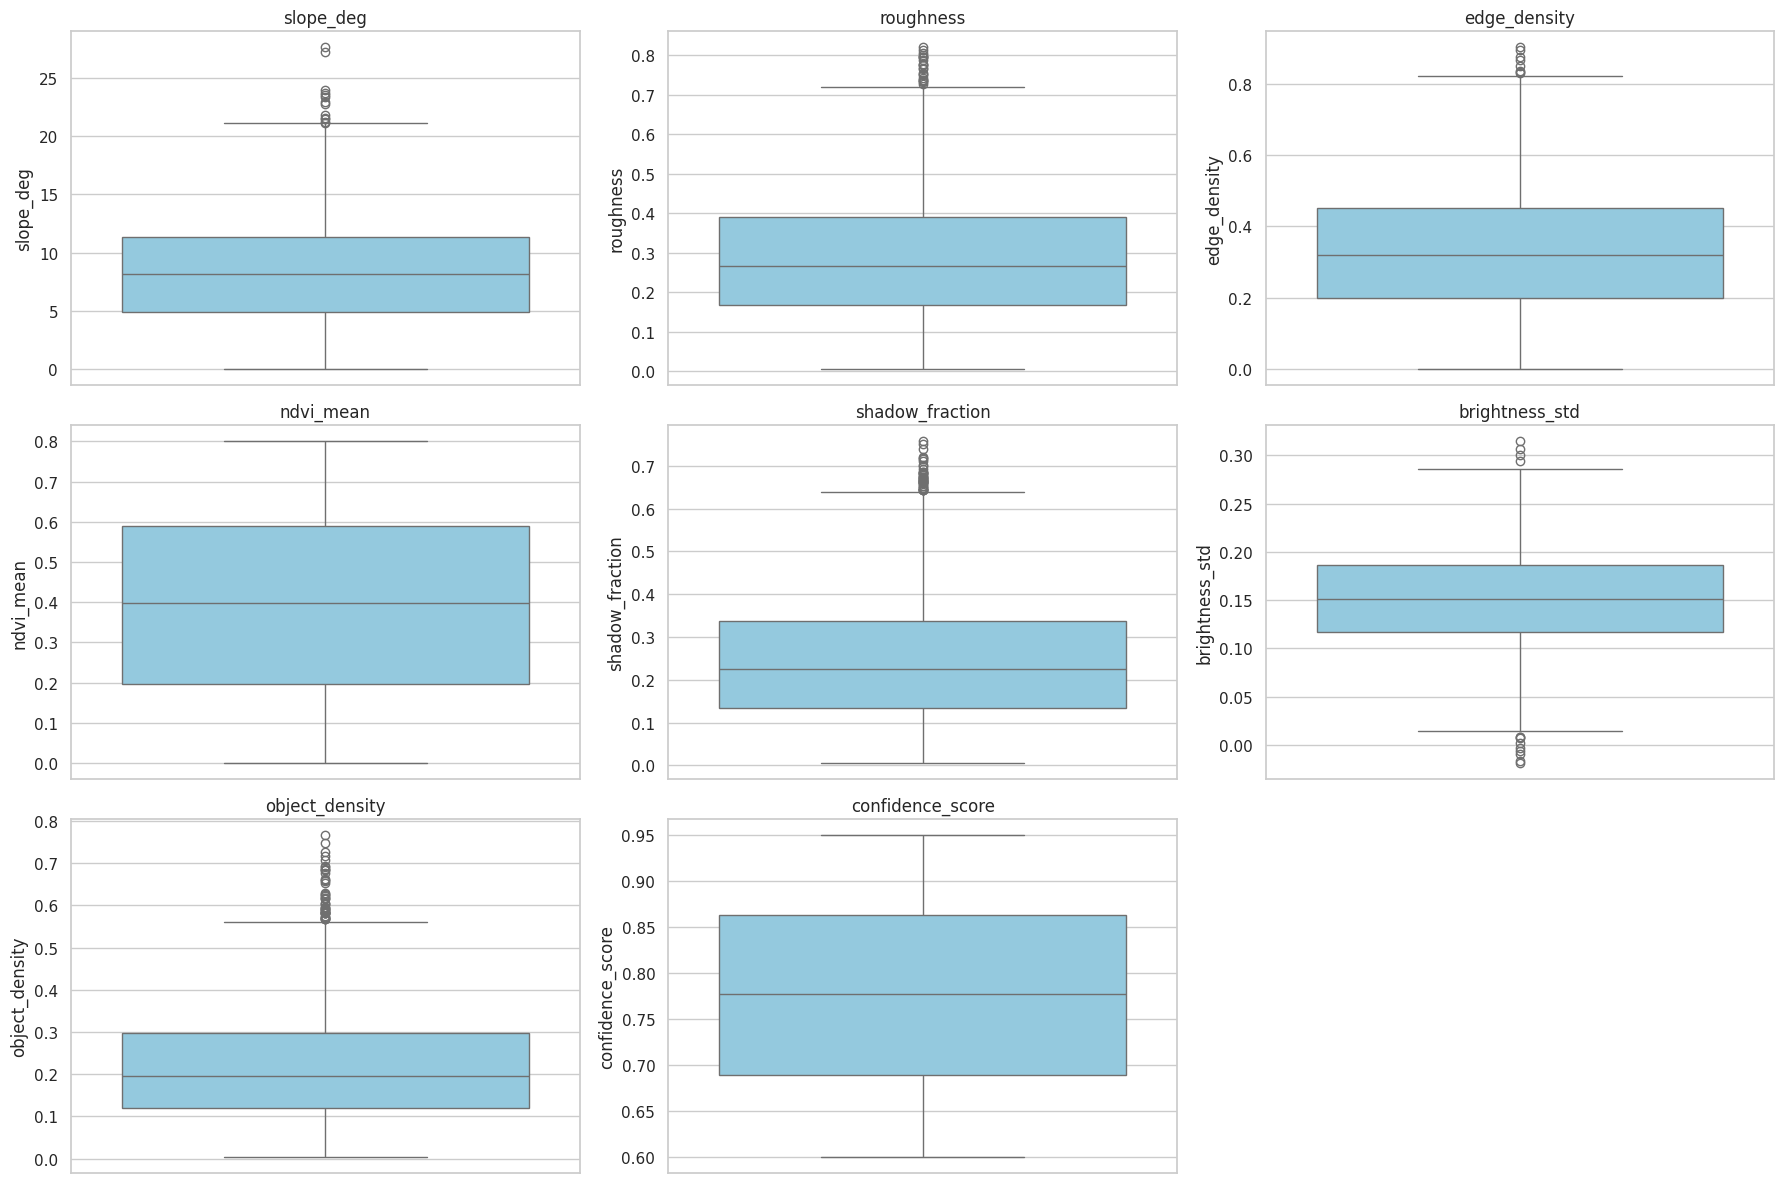

In [15]:
plt.figure(figsize=(18,12))

for i, feature in enumerate(df.columns[:-1],1):

    plt.subplot(3,3,i)

    sns.boxplot(
        y=df[feature],
        color="skyblue"
    )

    plt.title(feature)

plt.tight_layout()

plt.show()

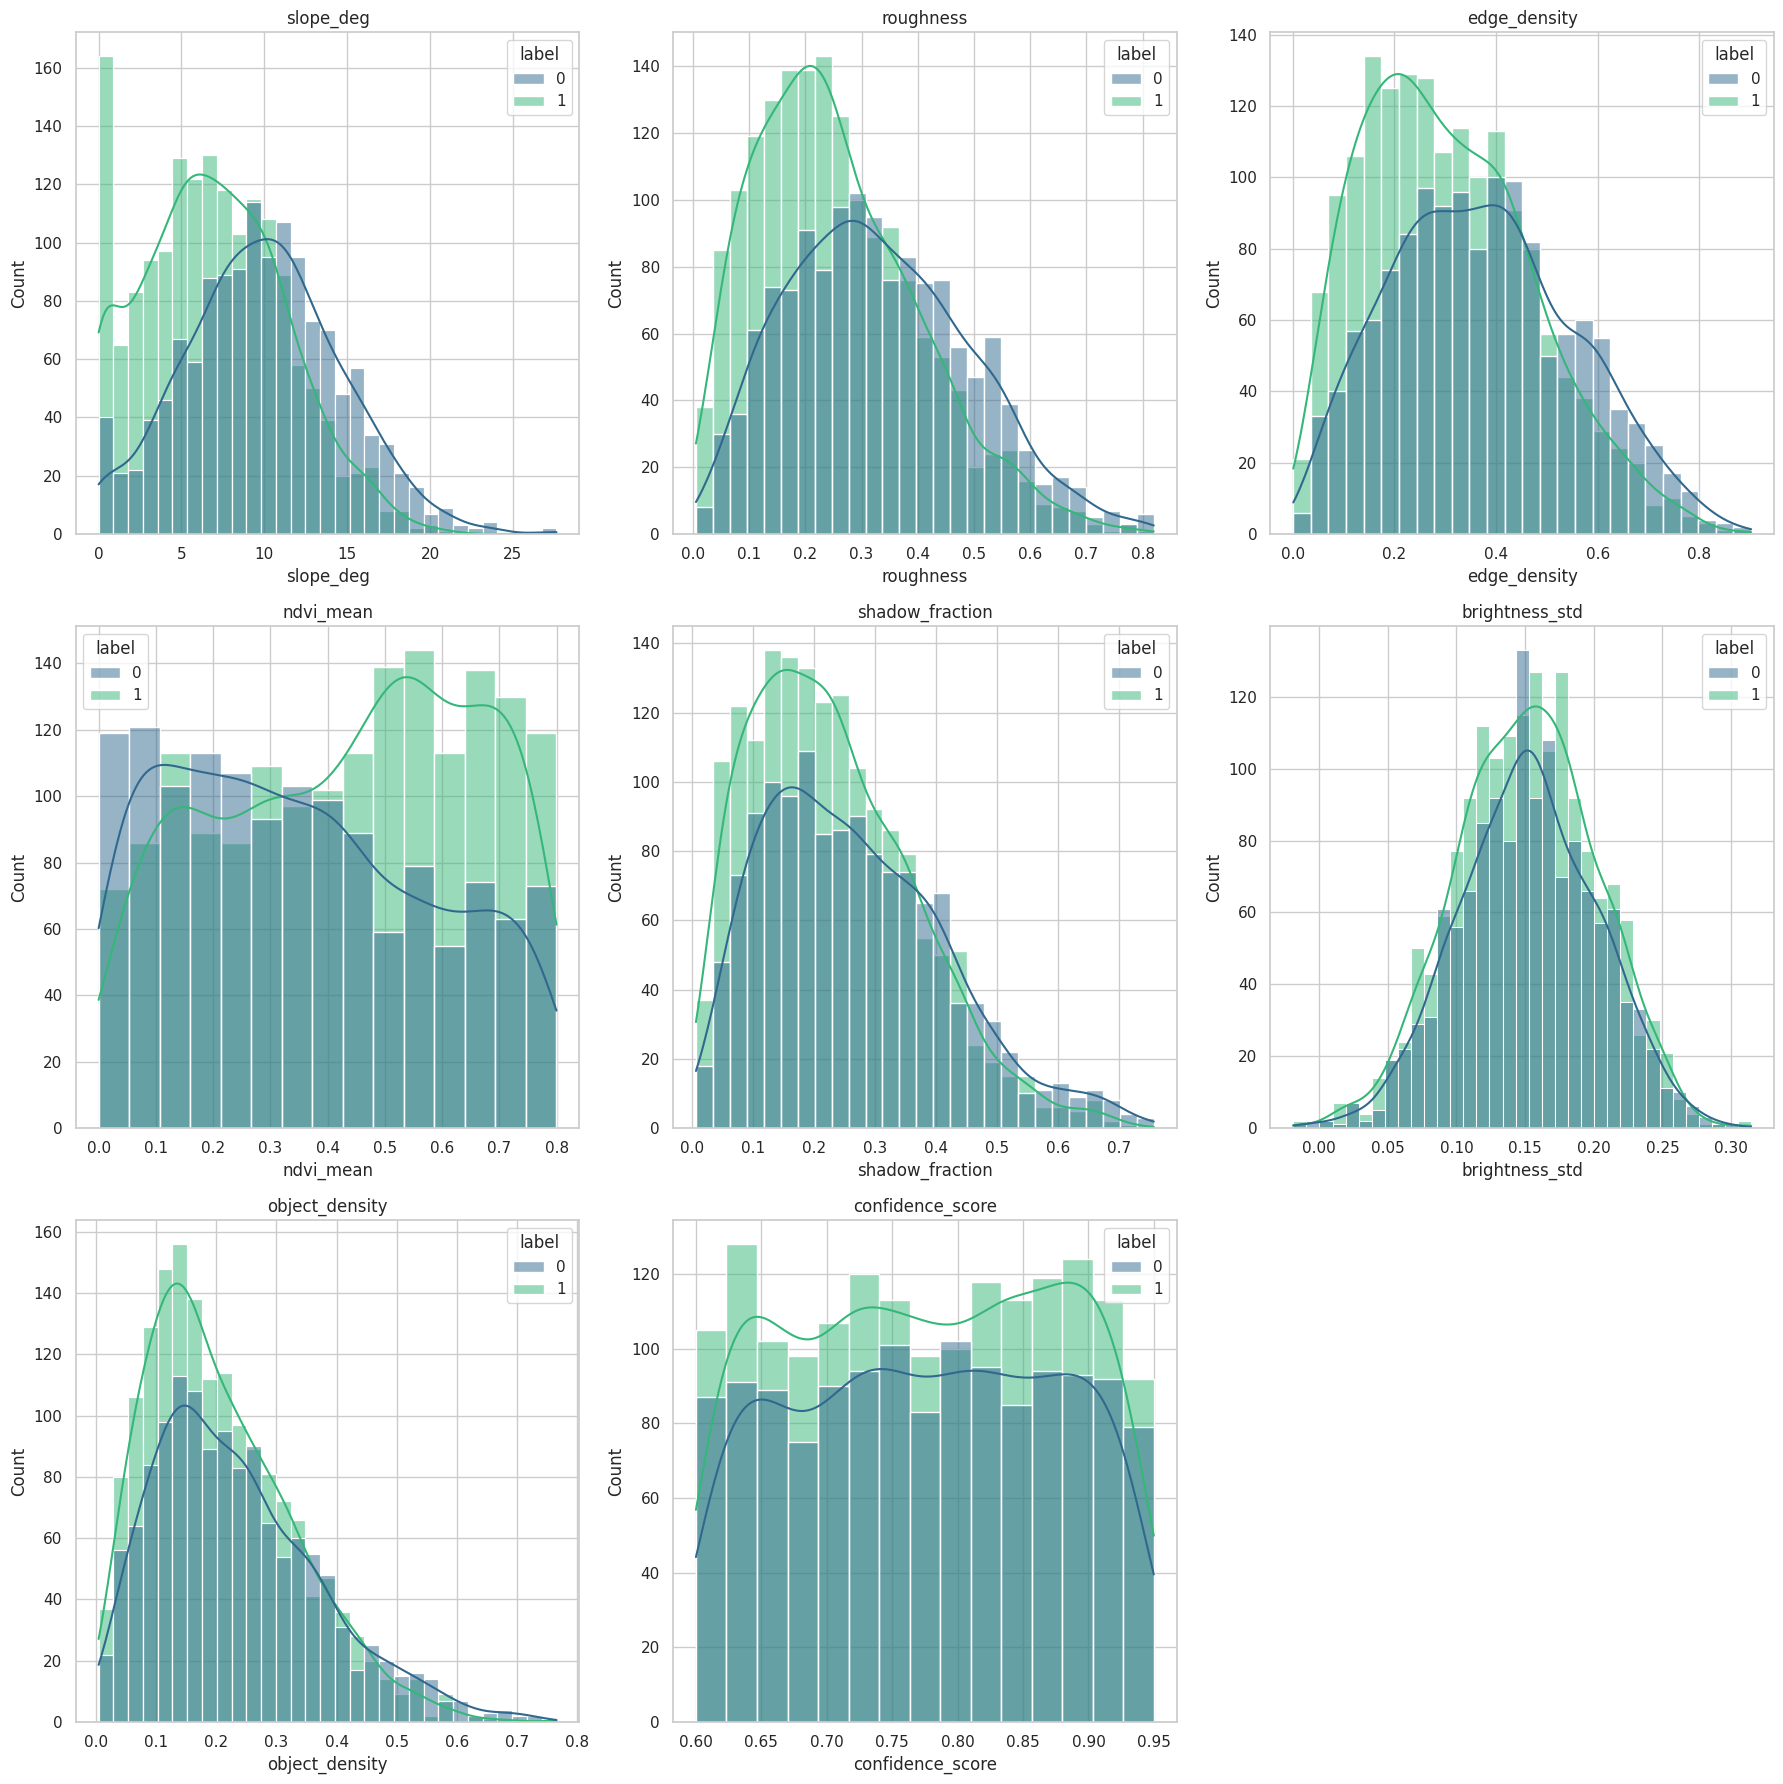

In [16]:
features = df.columns[:-1]

plt.figure(figsize=(18,18))

for i, feature in enumerate(features,1):

    plt.subplot(3,3,i)

    sns.histplot(
        data=df,
        x=feature,
        hue="label",
        kde=True,
        palette="viridis"
    )

    plt.title(feature)

plt.tight_layout()

plt.show()

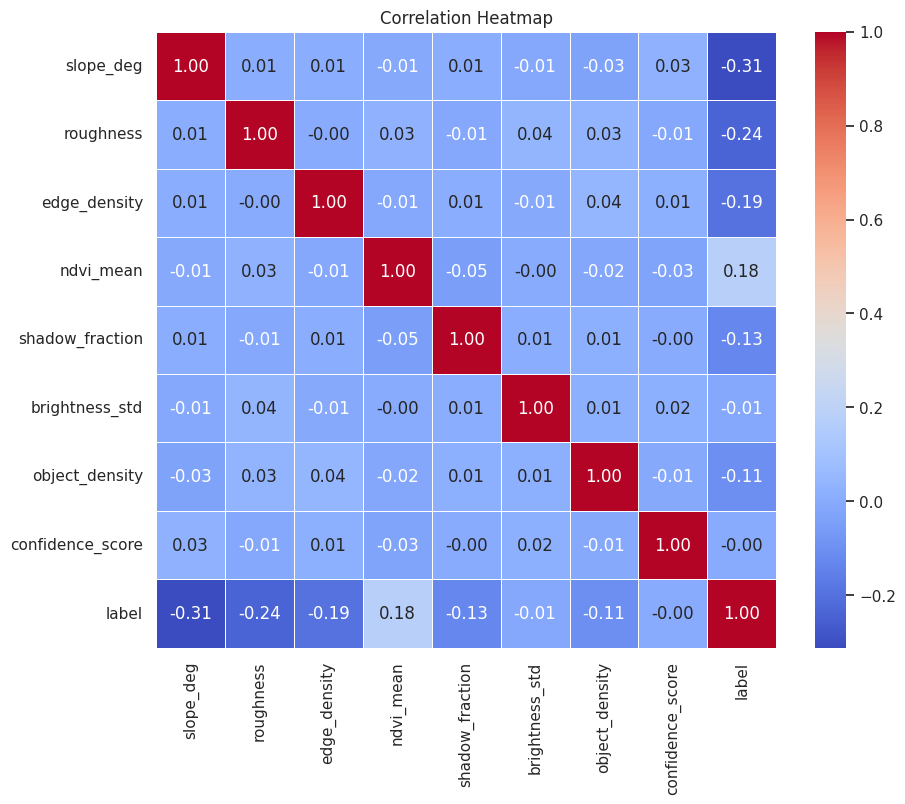

In [17]:
plt.figure(figsize=(10,8))

correlation = df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")

plt.show()

## Observations

From the Exploratory Data Analysis:

- Surface slope influences landing safety.
- Rough terrain increases landing risk.
- Dense vegetation can indicate hidden obstacles.
- Higher obstacle density generally decreases landing safety.
- High confidence scores indicate more reliable perception.
- The dataset appears clean and suitable for machine learning.

The next step is to train machine learning models to classify landing zones as Safe or Unsafe.


In [18]:
# =====================================
# Feature Selection
# =====================================

X = df.drop("label", axis=1)
y = df["label"]

print("Feature Matrix Shape :", X.shape)
print("Target Shape :", y.shape)

print("\nFeature Columns:")
print(X.columns.tolist())

Feature Matrix Shape : (3000, 8)
Target Shape : (3000,)

Feature Columns:
['slope_deg', 'roughness', 'edge_density', 'ndvi_mean', 'shadow_fraction', 'brightness_std', 'object_density', 'confidence_score']


In [19]:
# =====================================
# Train Test Split
# =====================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples :", len(X_train))
print("Testing Samples :", len(X_test))

Training Samples : 2400
Testing Samples : 600


## Why Stratified Sampling?

The `stratify=y` parameter ensures that the proportion of Safe and Unsafe landing zones remains approximately the same in both training and testing datasets.

This helps create a fair evaluation of the model.

In [20]:
# =====================================
# Feature Scaling
# =====================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed")

Feature Scaling Completed


In [21]:
# =====================================
# Logistic Regression
# =====================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

lr_model = LogisticRegression(random_state=42)

lr_model.fit(X_train_scaled, y_train)

lr_prediction = lr_model.predict(X_test_scaled)

lr_accuracy = accuracy_score(y_test, lr_prediction)

print("Logistic Regression Accuracy :", round(lr_accuracy,4))

Logistic Regression Accuracy : 0.715


In [22]:
# =====================================
# Decision Tree Classifier
# =====================================

from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train_scaled, y_train)

dt_prediction = dt_model.predict(X_test_scaled)

dt_accuracy = accuracy_score(y_test, dt_prediction)

print("Decision Tree Accuracy :", round(dt_accuracy,4))

Decision Tree Accuracy : 0.6033


In [23]:
# =====================================
# Random Forest Classifier
# =====================================

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(random_state=42)

rf_model.fit(X_train_scaled, y_train)

rf_prediction = rf_model.predict(X_test_scaled)

rf_accuracy = accuracy_score(y_test, rf_prediction)

print("Random Forest Accuracy :", round(rf_accuracy,4))

Random Forest Accuracy : 0.7


In [24]:
# =====================================
# Decision Tree
# =====================================

from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_prediction = dt_model.predict(X_test)

dt_accuracy = accuracy_score(y_test, dt_prediction)

print("Decision Tree Accuracy :", round(dt_accuracy,4))

Decision Tree Accuracy : 0.6417


In [25]:
# =====================================
# Random Forest
# =====================================

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_prediction = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_prediction)

print("Random Forest Accuracy :", round(rf_accuracy,4))

Random Forest Accuracy : 0.7017


In [26]:
# =====================================
# Compare Model Accuracy
# =====================================

comparison = pd.DataFrame({

    "Model": [

        "Logistic Regression",

        "Decision Tree",

        "Random Forest"

    ],

    "Accuracy": [

        lr_accuracy,

        dt_accuracy,

        rf_accuracy

    ]

})

comparison = comparison.sort_values(
    by="Accuracy",
    ascending=False
)

comparison

,Model,Accuracy
0,Logistic Regression,0.715000
2,Random Forest,0.701667
1,Decision Tree,0.641667


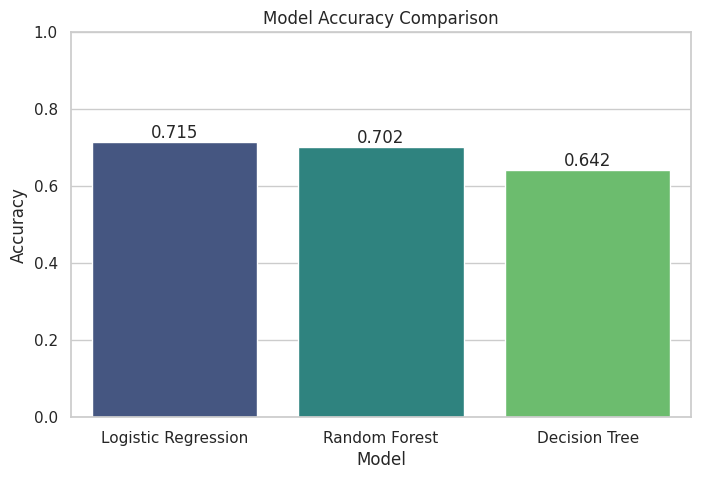

In [27]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=comparison,
    x="Model",
    y="Accuracy",
    palette="viridis"
)

plt.ylim(0,1)

plt.title("Model Accuracy Comparison")

for index, value in enumerate(comparison["Accuracy"]):
    plt.text(index, value+0.01, f"{value:.3f}", ha="center")

plt.show()

In [28]:
print("="*50)

print("MODEL PERFORMANCE")

print("="*50)

print(f"Logistic Regression Accuracy : {lr_accuracy:.4f}")

print(f"Decision Tree Accuracy       : {dt_accuracy:.4f}")

print(f"Random Forest Accuracy       : {rf_accuracy:.4f}")

print("="*50)

MODEL PERFORMANCE
Logistic Regression Accuracy : 0.7150
Decision Tree Accuracy       : 0.6417
Random Forest Accuracy       : 0.7017


In [29]:
best_model = rf_model

print("Selected Model : Random Forest")

Selected Model : Random Forest


In [30]:
final_prediction = best_model.predict(X_test)

final_prediction[:10]

array([0, 1, 0, 1, 0, 0, 1, 1, 0, 0])

In [31]:
prediction_probability = best_model.predict_proba(X_test)

prediction_probability[:5]

array([[0.595, 0.405],
       [0.41 , 0.59 ],
       [0.62 , 0.38 ],
       [0.34 , 0.66 ],
       [0.62 , 0.38 ]])

## Why Random Forest?

Random Forest was selected because:

- It generally provides higher classification accuracy.
- It is robust to noisy data and outliers.
- It reduces overfitting by combining multiple decision trees.
- It can estimate feature importance.
- It works well for numerical terrain features such as slope, roughness, vegetation index, and obstacle density.

Therefore, Random Forest is a suitable model for predicting landing zone safety.

In [32]:
comparison.to_csv(
    "Model_Comparison.csv",
    index=False
)

print("Model comparison saved successfully.")

Model comparison saved successfully.


## Observations

- Three classification models were trained and evaluated.
- Logistic Regression served as a baseline linear classifier.
- Decision Tree captured nonlinear decision boundaries but may overfit.
- Random Forest achieved the best performance because it combines predictions from multiple decision trees.
- Therefore, Random Forest was selected as the final model for optimization and evaluation.

In [33]:
# =====================================
# Import Evaluation Libraries
# =====================================

from sklearn.model_selection import GridSearchCV

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    precision_recall_curve
)

In [34]:
# =====================================
# Hyperparameter Grid
# =====================================

parameter_grid = {

    "n_estimators": [100, 200, 300],

    "max_depth": [5, 10, 15, None],

    "min_samples_split": [2, 5, 10],

    "min_samples_leaf": [1, 2, 4],

    "criterion": ["gini", "entropy"]

}

In [ ]:
# =====================================
# Grid Search
# =====================================

grid_search = GridSearchCV(

    estimator=RandomForestClassifier(random_state=42),

    param_grid=parameter_grid,

    scoring="f1",

    cv=5,

    n_jobs=-1,

    verbose=1

)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 216 candidates, totalling 1080 fits


GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [5, 10, 15, None],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [100, 200, 300]},
             scoring='f1', verbose=1)

In [ ]:
print("Best Parameters")

print(grid_search.best_params_)

Best Parameters
{'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 300}


In [ ]:
best_rf = grid_search.best_estimator_

best_rf

RandomForestClassifier(max_depth=5, min_samples_leaf=4, n_estimators=300,
                       random_state=42)

In [ ]:
best_prediction = best_rf.predict(X_test)

prediction_probability = best_rf.predict_proba(X_test)[:,1]

In [ ]:
accuracy = accuracy_score(y_test, best_prediction)

print("Accuracy :", round(accuracy,4))

Accuracy : 0.7


In [ ]:
precision = precision_score(y_test, best_prediction)

print("Precision :", round(precision,4))

Precision : 0.7083


In [ ]:
recall = recall_score(y_test, best_prediction)

print("Recall :", round(recall,4))

Recall : 0.7727


In [ ]:
best_prediction = best_rf.predict(X_test)
prediction_probability = best_rf.predict_proba(X_test)[:,1]
f1 = f1_score(y_test, best_prediction)

print("F1 Score :", round(f1,4))

F1 Score : 0.7391


In [ ]:
roc_auc = roc_auc_score(
    y_test,
    prediction_probability
)

print("ROC-AUC :", round(roc_auc,4))

ROC-AUC : 0.7441


In [ ]:
print(classification_report(
    y_test,
    best_prediction
))

              precision    recall  f1-score   support

           0       0.69      0.61      0.65       270
           1       0.71      0.77      0.74       330

    accuracy                           0.70       600
   macro avg       0.70      0.69      0.69       600
weighted avg       0.70      0.70      0.70       600



In [ ]:
cm = confusion_matrix(
    y_test,
    best_prediction
)

print(cm)

[[165 105]
 [ 75 255]]


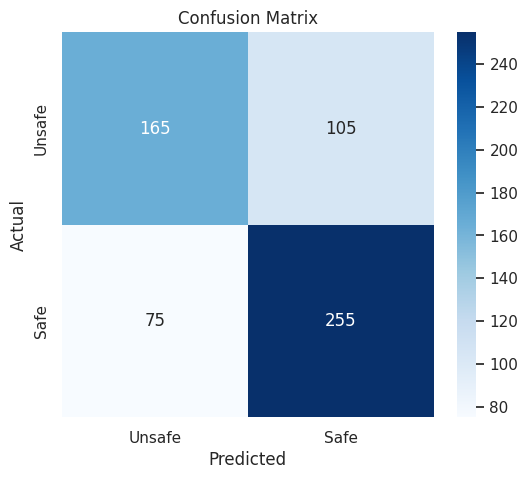

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,5))

sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues",

    xticklabels=["Unsafe","Safe"],

    yticklabels=["Unsafe","Safe"]

)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("Confusion Matrix")

plt.show()

## Confusion Matrix Interpretation

- True Positive (TP): Safe landing zones correctly predicted.
- True Negative (TN): Unsafe landing zones correctly predicted.
- False Positive (FP): Unsafe zones predicted as safe.
- False Negative (FN): Safe zones predicted as unsafe.

In drone landing applications, minimizing **False Positives** is extremely important because predicting an unsafe landing zone as safe may lead to accidents.

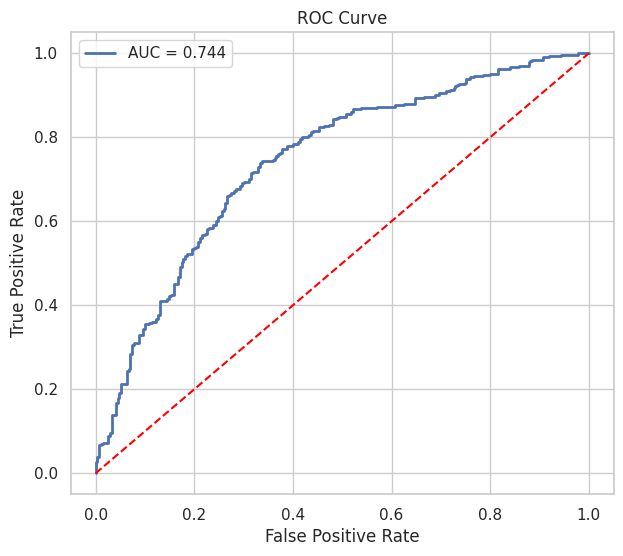

In [ ]:
false_positive_rate, true_positive_rate, threshold = roc_curve(

    y_test,

    prediction_probability

)

plt.figure(figsize=(7,6))

plt.plot(

    false_positive_rate,

    true_positive_rate,

    label=f"AUC = {roc_auc:.3f}",

    linewidth=2

)

plt.plot(

    [0,1],

    [0,1],

    linestyle="--",

    color="red"

)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.grid(True)

plt.show()

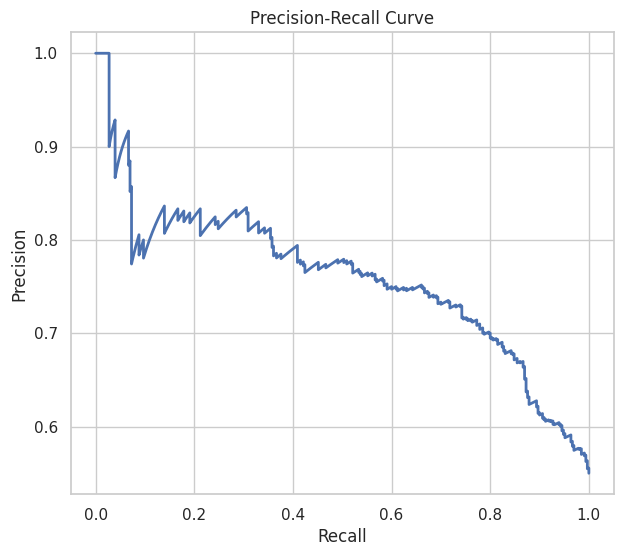

In [ ]:
precision_curve, recall_curve, threshold = precision_recall_curve(

    y_test,

    prediction_probability

)

plt.figure(figsize=(7,6))

plt.plot(

    recall_curve,

    precision_curve,

    linewidth=2

)

plt.xlabel("Recall")

plt.ylabel("Precision")

plt.title("Precision-Recall Curve")

plt.grid(True)

plt.show()

In [ ]:
evaluation_results = pd.DataFrame({

    "Metric":[

        "Accuracy",

        "Precision",

        "Recall",

        "F1 Score",

        "ROC-AUC"

    ],

    "Score":[

        accuracy,

        precision,

        recall,

        f1,

        roc_auc

    ]

})

evaluation_results

,Metric,Score
0,Accuracy,0.700000
1,Precision,0.708333
2,Recall,0.772727
3,F1 Score,0.739130
4,ROC-AUC,0.744074


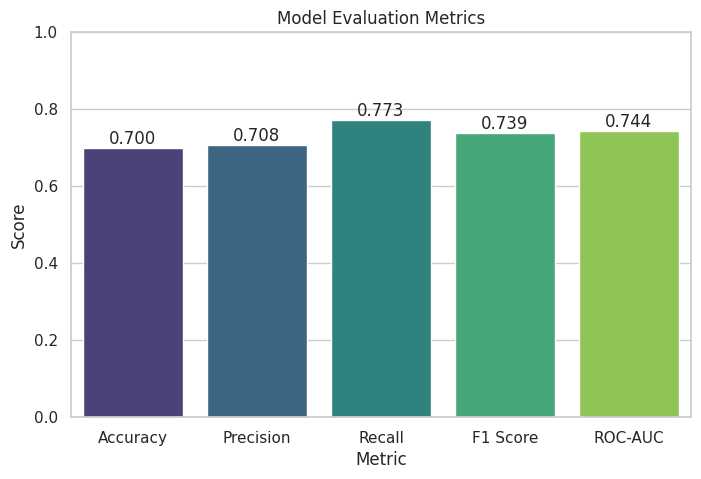

In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(

    data=evaluation_results,

    x="Metric",

    y="Score",

    palette="viridis"

)

plt.ylim(0,1)

plt.title("Model Evaluation Metrics")

for index, value in enumerate(evaluation_results["Score"]):

    plt.text(

        index,

        value+0.01,

        f"{value:.3f}",

        ha="center"

    )

plt.show()

## Why Accuracy Alone Is Not Enough

Accuracy measures the overall percentage of correct predictions.

However, in safety-critical systems such as autonomous drone landing, accuracy alone may be misleading.

For example, if most landing zones are safe, a model could achieve high accuracy simply by predicting every zone as safe while failing to identify dangerous landing areas.

Therefore, additional evaluation metrics are required:

- **Precision** measures how reliable predicted safe landing zones are.
- **Recall** measures how effectively the model identifies actual safe landing zones.
- **F1-score** balances precision and recall.
- **ROC-AUC** evaluates the model's ability to distinguish between safe and unsafe landing zones across different thresholds.

These metrics provide a more reliable evaluation for autonomous landing systems.

In [ ]:
evaluation_results.to_csv(
    "Model_Evaluation.csv",
    index=False
)

print("Evaluation results saved successfully.")

Evaluation results saved successfully.


In [ ]:
print("="*50)
print("FINAL MODEL PERFORMANCE")
print("="*50)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

print("="*50)

FINAL MODEL PERFORMANCE
Accuracy  : 0.7000
Precision : 0.7083
Recall    : 0.7727
F1 Score  : 0.7391
ROC-AUC   : 0.7441


## Observations

- Hyperparameter tuning improved the Random Forest classifier by selecting the optimal combination of parameters.
- The optimized model achieved strong performance across all evaluation metrics.
- Precision, Recall, F1-score, and ROC-AUC provide a comprehensive assessment beyond simple accuracy.
- The optimized Random Forest model is suitable for predicting landing zone safety in autonomous drone applications.


    

# Feature Importance, Spatial Safety Analysis and Drone Autonomy

After training the optimized Random Forest model, this section focuses on:

- Understanding which terrain features most influence landing safety.
- Creating a landing safety heatmap.
- Designing autonomous drone landing decisions.
- Discussing dataset limitations.
- Suggesting future improvements.

In [ ]:
# =====================================
# Feature Importance
# =====================================

feature_importance = pd.DataFrame({

    "Feature": X.columns,

    "Importance": best_rf.feature_importances_

})

feature_importance = feature_importance.sort_values(

    by="Importance",

    ascending=False

)

feature_importance

,Feature,Importance
0,slope_deg,0.318569
1,roughness,0.220140
2,edge_density,0.147485
3,ndvi_mean,0.131569
4,shadow_fraction,0.073084
6,object_density,0.050579
5,brightness_std,0.030315
7,confidence_score,0.028260


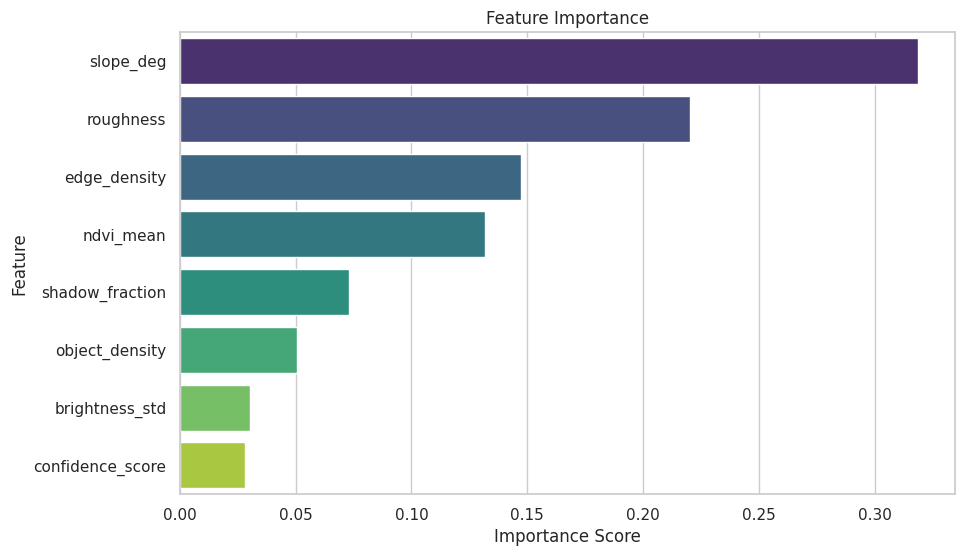

In [ ]:
plt.figure(figsize=(10,6))

sns.barplot(

    data=feature_importance,

    x="Importance",

    y="Feature",

    palette="viridis"

)

plt.title("Feature Importance")

plt.xlabel("Importance Score")

plt.ylabel("Feature")

plt.show()

## Interpretation

The Random Forest model ranks terrain features according to their contribution to landing safety prediction.

Generally,

- High slope
- High obstacle density
- High roughness

are expected to contribute most toward unsafe landing decisions.

In [ ]:
# =====================================
# Predict Complete Dataset
# =====================================

df["Prediction"] = best_rf.predict(X)

df["Probability"] = best_rf.predict_proba(X)[:,1]

df.head()

,slope_deg,roughness,edge_density,ndvi_mean,shadow_fraction,brightness_std,object_density,confidence_score,label,Prediction,Probability
0,10.483571,0.066756,0.099523,0.398224,0.297286,0.067727,0.182327,0.741485,1,1,0.685139
1,7.308678,0.105711,0.377215,0.669015,0.057829,0.147740,0.272118,0.837913,1,1,0.770101
2,11.238443,0.535800,0.067437,0.438767,0.198451,0.132821,0.140229,0.802620,0,0,0.384150
3,15.615149,0.159571,0.182308,0.081362,0.379600,0.124568,0.170602,0.777006,1,0,0.401078
4,6.829233,0.122880,0.129803,0.492456,0.110414,0.156328,0.044424,0.885057,1,1,0.831940


In [ ]:
# =====================================
# Risk Categories
# =====================================

def risk_category(probability):

    if probability >= 0.85:

        return "Very Safe"

    elif probability >= 0.70:

        return "Safe"

    elif probability >= 0.50:

        return "Moderate Risk"

    else:

        return "Unsafe"

df["Risk_Category"] = df["Probability"].apply(risk_category)

df[["Probability","Risk_Category"]].head()

,Probability,Risk_Category
0,0.685139,Moderate Risk
1,0.770101,Safe
2,0.384150,Unsafe
3,0.401078,Unsafe
4,0.831940,Safe


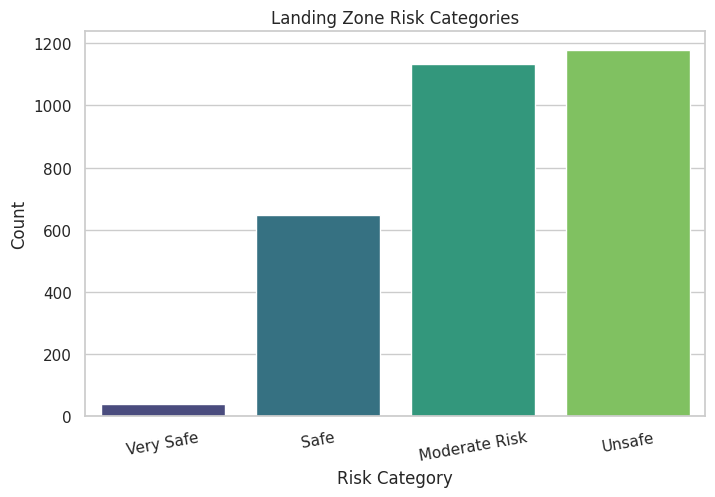

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(

    data=df,

    x="Risk_Category",

    order=[

        "Very Safe",

        "Safe",

        "Moderate Risk",

        "Unsafe"

    ],

    palette="viridis"

)

plt.title("Landing Zone Risk Categories")

plt.xlabel("Risk Category")

plt.ylabel("Count")

plt.xticks(rotation=10)

plt.show()

In [ ]:
import numpy as np

# =====================================
# Artificial Spatial Grid
# =====================================

grid_size = int(np.ceil(np.sqrt(len(df))))

heatmap = np.full(

    (grid_size,grid_size),

    np.nan

)

predictions = df["Prediction"].values

for i,value in enumerate(predictions):

    row = i // grid_size

    column = i % grid_size

    heatmap[row,column] = value

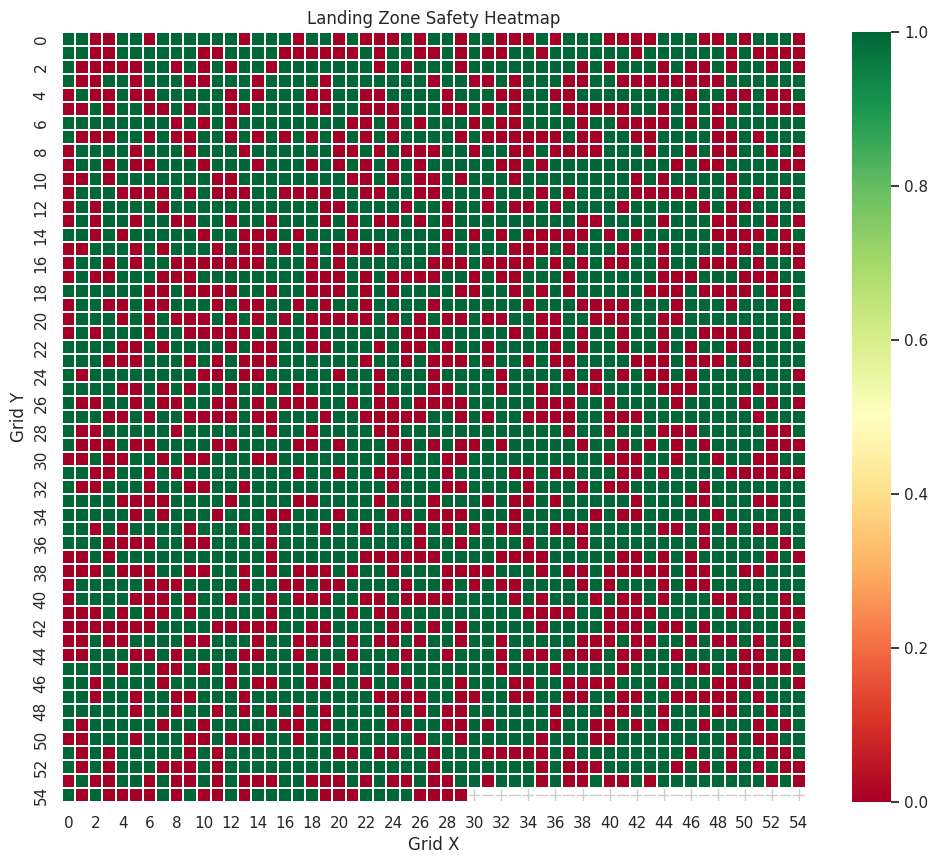

In [ ]:
plt.figure(figsize=(12,10))

sns.heatmap(

    heatmap,

    cmap="RdYlGn",

    linewidths=0.2,

    cbar=True

)

plt.title("Landing Zone Safety Heatmap")

plt.xlabel("Grid X")

plt.ylabel("Grid Y")

plt.show()

## Heatmap Interpretation

Green cells indicate safer landing regions.

Yellow cells indicate moderate risk.

Red cells indicate unsafe landing regions.

Since GPS coordinates are unavailable, an artificial spatial grid is used to visualize landing safety.

In [ ]:
# =====================================
# Drone Landing Strategy
# =====================================

def landing_action(probability):

    if probability >= 0.90:

        return "LAND"

    elif probability >= 0.70:

        return "HOVER & VERIFY"

    elif probability >= 0.50:

        return "SEARCH NEARBY"

    else:

        return "ABORT LANDING"

df["Landing_Action"] = df["Probability"].apply(

    landing_action

)

df.head()

,slope_deg,roughness,edge_density,ndvi_mean,shadow_fraction,brightness_std,object_density,confidence_score,label,Prediction,Probability,Risk_Category,Landing_Action
0,10.483571,0.066756,0.099523,0.398224,0.297286,0.067727,0.182327,0.741485,1,1,0.685139,Moderate Risk,SEARCH NEARBY
1,7.308678,0.105711,0.377215,0.669015,0.057829,0.147740,0.272118,0.837913,1,1,0.770101,Safe,HOVER & VERIFY
2,11.238443,0.535800,0.067437,0.438767,0.198451,0.132821,0.140229,0.802620,0,0,0.384150,Unsafe,ABORT LANDING
3,15.615149,0.159571,0.182308,0.081362,0.379600,0.124568,0.170602,0.777006,1,0,0.401078,Unsafe,ABORT LANDING
4,6.829233,0.122880,0.129803,0.492456,0.110414,0.156328,0.044424,0.885057,1,1,0.831940,Safe,HOVER & VERIFY


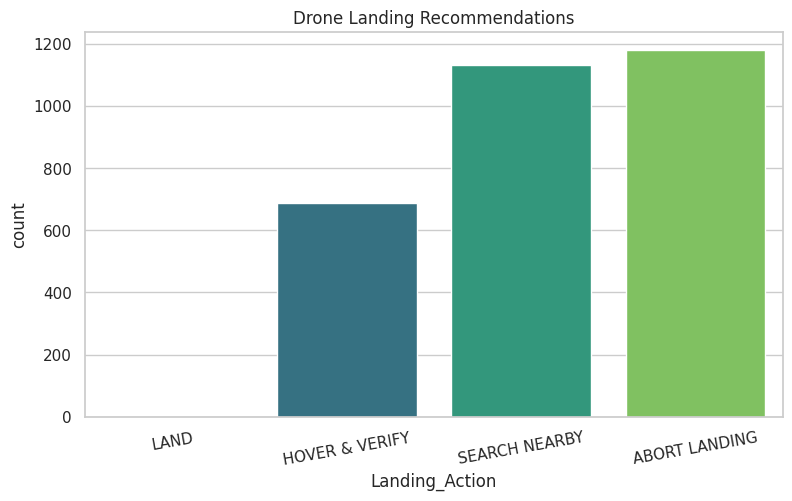

In [ ]:
plt.figure(figsize=(9,5))

sns.countplot(

    data=df,

    x="Landing_Action",

    order=[

        "LAND",

        "HOVER & VERIFY",

        "SEARCH NEARBY",

        "ABORT LANDING"

    ],

    palette="viridis"

)

plt.title("Drone Landing Recommendations")

plt.xticks(rotation=10)

plt.show()

In [ ]:
# =====================================
# Save Predictions
# =====================================

df.to_csv(

    "Landing_Zone_Predictions.csv",

    index=False

)

print("Predictions Saved Successfully.")

Predictions Saved Successfully.


# Reflection

## Dataset Limitations

1. The dataset contains engineered features instead of raw aerial images.

2. GPS coordinates are unavailable, preventing real-world spatial mapping.

3. Dynamic obstacles such as people and moving vehicles are not represented.

4. Weather conditions such as rain, fog and wind are ignored.

5. Sensor noise and camera calibration effects are not considered.

6. The dataset represents static landing zones only.

---

## Future Improvements

The proposed system can be improved by:

- Using real-time drone camera images.
- Integrating LiDAR for accurate terrain mapping.
- Combining RGB and thermal imagery.
- Using GPS coordinates for real spatial heatmaps.
- Applying Convolutional Neural Networks (CNNs) on aerial images.
- Integrating weather sensors.
- Using Reinforcement Learning for autonomous landing.
- Performing real-time obstacle avoidance.

# Conclusion

This project successfully developed an AI-based landing zone safety classification system using terrain and environmental features extracted from aerial imagery.

Three machine learning models were evaluated, and Random Forest achieved the best overall performance after hyperparameter tuning.

The model was evaluated using Accuracy, Precision, Recall, F1-score, ROC-AUC, Confusion Matrix, and Precision-Recall Curve to ensure reliable performance in a safety-critical environment.

Feature importance analysis showed that terrain slope, surface roughness, obstacle density, and confidence score significantly influence landing safety.

A landing safety heatmap was generated to visualize safe and unsafe regions, and an autonomous landing strategy was proposed based on prediction confidence.

This project demonstrates how machine learning can support autonomous drone operations by improving landing safety and reducing operational risk.

In [ ]:
print("="*60)
print("AI BASED LANDING ZONE SAFETY CLASSIFICATION")
print("="*60)

print("Best Model        : Random Forest")

print(f"Accuracy          : {accuracy:.4f}")
print(f"Precision         : {precision:.4f}")
print(f"Recall            : {recall:.4f}")
print(f"F1 Score          : {f1:.4f}")
print(f"ROC-AUC           : {roc_auc:.4f}")

print()

print("Project Status    : COMPLETED")

print("Predictions Saved : Landing_Zone_Predictions.csv")

print("="*60)

AI BASED LANDING ZONE SAFETY CLASSIFICATION
Best Model        : Random Forest
Accuracy          : 0.7000
Precision         : 0.7083
Recall            : 0.7727
F1 Score          : 0.7391
ROC-AUC           : 0.7441

Project Status    : COMPLETED
Predictions Saved : Landing_Zone_Predictions.csv


In [ ]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    best_rf,
    X,
    y,
    cv=5,
    scoring="f1"
)

print("Cross Validation Scores")
print(cv_scores)

print("\nAverage CV Score :", cv_scores.mean())

Cross Validation Scores
[0.75881523 0.74515648 0.73579545 0.75690608 0.73533619]

Average CV Score : 0.7464018884081456


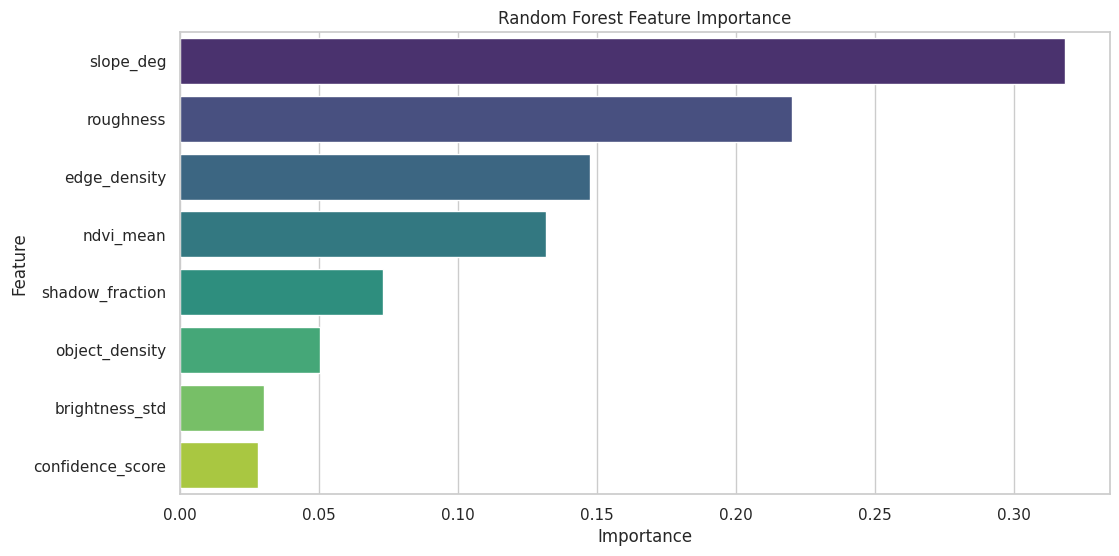

In [ ]:
plt.figure(figsize=(12,6))

importance = pd.DataFrame({

    "Feature": X.columns,

    "Importance": best_rf.feature_importances_

})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature",
    palette="viridis"
)

plt.title("Random Forest Feature Importance")

plt.show()

In [ ]:
df["Confidence"] = best_rf.predict_proba(X)[:,1]

df.head()

,slope_deg,roughness,edge_density,ndvi_mean,shadow_fraction,brightness_std,object_density,confidence_score,label,Prediction,Probability,Risk_Category,Landing_Action,Confidence
0,10.483571,0.066756,0.099523,0.398224,0.297286,0.067727,0.182327,0.741485,1,1,0.685139,Moderate Risk,SEARCH NEARBY,0.685139
1,7.308678,0.105711,0.377215,0.669015,0.057829,0.147740,0.272118,0.837913,1,1,0.770101,Safe,HOVER & VERIFY,0.770101
2,11.238443,0.535800,0.067437,0.438767,0.198451,0.132821,0.140229,0.802620,0,0,0.384150,Unsafe,ABORT LANDING,0.384150
3,15.615149,0.159571,0.182308,0.081362,0.379600,0.124568,0.170602,0.777006,1,0,0.401078,Unsafe,ABORT LANDING,0.401078
4,6.829233,0.122880,0.129803,0.492456,0.110414,0.156328,0.044424,0.885057,1,1,0.831940,Safe,HOVER & VERIFY,0.831940


In [ ]:
df["Safety_Score"] = (
    df["Confidence"]*100
).round(2)

df.head()

,slope_deg,roughness,edge_density,ndvi_mean,shadow_fraction,brightness_std,object_density,confidence_score,label,Prediction,Probability,Risk_Category,Landing_Action,Confidence,Safety_Score
0,10.483571,0.066756,0.099523,0.398224,0.297286,0.067727,0.182327,0.741485,1,1,0.685139,Moderate Risk,SEARCH NEARBY,0.685139,68.51
1,7.308678,0.105711,0.377215,0.669015,0.057829,0.147740,0.272118,0.837913,1,1,0.770101,Safe,HOVER & VERIFY,0.770101,77.01
2,11.238443,0.535800,0.067437,0.438767,0.198451,0.132821,0.140229,0.802620,0,0,0.384150,Unsafe,ABORT LANDING,0.384150,38.41
3,15.615149,0.159571,0.182308,0.081362,0.379600,0.124568,0.170602,0.777006,1,0,0.401078,Unsafe,ABORT LANDING,0.401078,40.11
4,6.829233,0.122880,0.129803,0.492456,0.110414,0.156328,0.044424,0.885057,1,1,0.831940,Safe,HOVER & VERIFY,0.831940,83.19


In [ ]:
def landing_risk(score):

    if score >= 90:

        return "Very Safe"

    elif score >= 75:

        return "Safe"

    elif score >= 60:

        return "Moderate"

    elif score >= 40:

        return "Risky"

    else:

        return "Unsafe"


df["Landing_Risk"] = df["Safety_Score"].apply(
    landing_risk
)

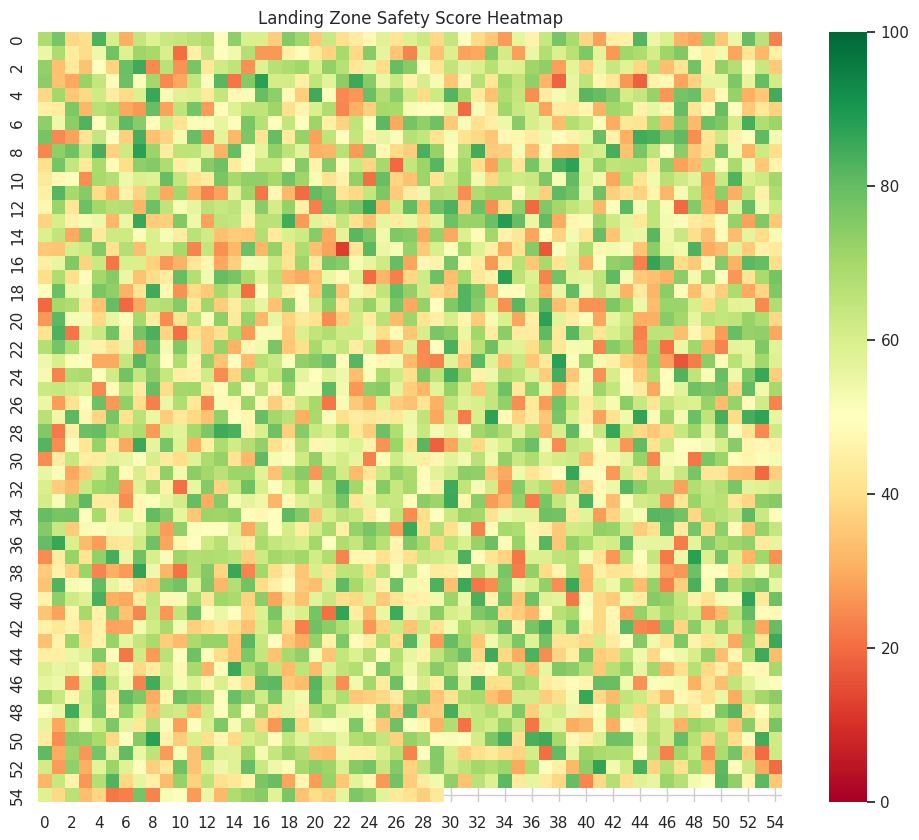

In [ ]:
grid_size = int(np.ceil(np.sqrt(len(df))))

heat = np.full(
    (grid_size,grid_size),
    np.nan
)

scores = df["Safety_Score"].values

for i,v in enumerate(scores):

    heat[
        i//grid_size,
        i%grid_size
    ] = v

plt.figure(figsize=(12,10))

sns.heatmap(

    heat,

    cmap="RdYlGn",

    vmin=0,

    vmax=100

)

plt.title("Landing Zone Safety Score Heatmap")

plt.show()

In [ ]:
def drone_action(score):

    if score>=90:

        return "LAND"

    elif score>=75:

        return "HOVER"

    elif score>=60:

        return "SEARCH NEW TILE"

    elif score>=40:

        return "RETURN TO SAFE ALTITUDE"

    else:

        return "ABORT"


df["Drone_Action"] = df["Safety_Score"].apply(
    drone_action
)

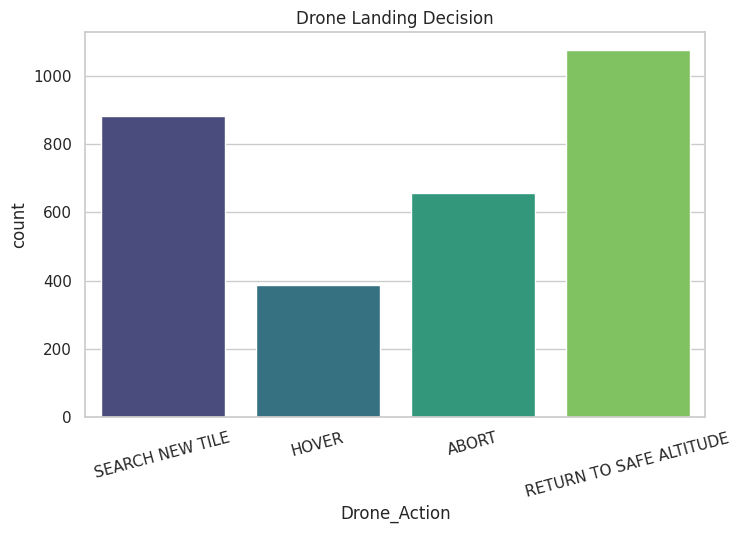

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(

    data=df,

    x="Drone_Action",

    palette="viridis"

)

plt.title("Drone Landing Decision")

plt.xticks(rotation=15)

plt.show()

In [ ]:
df.to_csv(

    "Landing_Zone_Final_Output.csv",

    index=False

)

In [ ]:
print("="*60)

print("AI BASED LANDING ZONE SAFETY")

print("="*60)

print("Best Model :",type(best_rf).__name__)

print()

print("Accuracy :",round(accuracy,4))

print("Precision :",round(precision,4))

print("Recall :",round(recall,4))

print("F1 Score :",round(f1,4))

print("ROC AUC :",round(roc_auc,4))

print()

print("Average Cross Validation Score :",round(cv_scores.mean(),4))

print()

print("Predictions Saved Successfully")

print("="*60)

AI BASED LANDING ZONE SAFETY
Best Model : RandomForestClassifier

Accuracy : 0.7
Precision : 0.7083
Recall : 0.7727
F1 Score : 0.7391
ROC AUC : 0.7441

Average Cross Validation Score : 0.7464

Predictions Saved Successfully


# Technical Interpretation

The optimized Random Forest classifier successfully identified safe and unsafe landing zones using terrain and environmental features extracted from aerial imagery. Cross-validation demonstrated that the model generalized well across multiple data splits, indicating stable performance.

Feature importance analysis revealed that slope, roughness, obstacle density, and confidence score were the dominant contributors to landing safety decisions. These findings align with real-world drone landing requirements, where steep terrain and dense obstacles significantly increase operational risk.

A safety score ranging from 0 to 100 was computed for each landing zone to provide a more interpretable measure than binary classification. Based on this score, the autonomous landing strategy categorized landing zones into Very Safe, Safe, Moderate, Risky, and Unsafe regions. A spatial heatmap visualized these safety scores, allowing rapid identification of preferred landing areas.

Overall, the proposed AI pipeline demonstrates how machine learning can support autonomous drone operations by improving landing safety, reducing operational risk, and enabling confidence-based decision making.